# C08b — RoBERTa: six competitors, OG+RAFT, NS10 and NS11

Run in a fresh kernel inside `reproduction/`. Uses the **saved C07b RAID-trained RoBERTa checkpoint**. No base-detector retraining or new rewrite generation. Reads ten matched arms: OG, NS10, six C08 competitors, OG→RAFT and NS11=RAFT(NS10).

**Inputs:** all 54 texts per arm are required. Paths are editable in the first code cell. OG→RAFT defaults to `R01_published_local_v3/RAFT_adaptation20_34/RAFT_texts54.csv`; NS11 defaults to `R11_NS10_RAFT_v1/NS11_texts.csv`. No silent fallback to ten-case development outputs. Known RAFT/NS11 fidelity caveats remain; these are generator-substituted local attacks, not exact original-paper reproductions. They used this frozen RoBERTa as attack guidance, so their evaluation is detector-aware, not zero-shot transfer.

**Adaptation:** carry forward the `< .8` full-cohort frozen AUROC rule to every non-OG arm, including NS10, RAFT and NS11. Use the previously saved C07b random 20/34 source split for all methods. Each selected arm gets its own continued full-model fine-tune initialized from frozen C07b, on original RAID training examples plus twenty own-arm positives. Select checkpoints by original RAID validation loss. A separate RAID-only continuation control uses the same saved adaptation hyperparameters. This distinguishes additional training from attack-example exposure.

This notebook creates **new, resumable C08b continuation runs**, including selected NS10/RAFT/NS11 arms, rather than assuming older adapted checkpoints have identical provenance. It does not overwrite those checkpoints. Training may take longer than scoring. Training resumes at the most recent Trainer checkpoint; document scoring resumes after each completed text. Only one detector is loaded at a time.

Reuse the environment that can load your saved RoBERTa and `training_args.bin`; no automatic package changes. Scores use FP32 parameters with BF16 autocast and the original 512-token prefix. C08b has separate runtime-aware scoring caches; it does not relabel old C07b/R01 caches after dependency changes. Original texts/models remain untouched. The protocol records actual data/model identities, not notebook-source hashes.

Selection is based on all 54 frozen outcomes, including the eventual held-out 34: adaptation analyses are exploratory conditional comparisons. Human reference weights match the evaluated cohort; thresholds use validation humans only. Paired bootstrap intervals condition on the chosen split, fitted models and fixed human references.

All figures are combined comparisons rather than one plot per method. PNG/PDF exports go to both the run directory and `reproduction/figures/`. NS10 remains the main endpoint; NS11 is the compatibility extension.


## Setup and paths

In [1]:
from pathlib import Path
import os,json,hashlib,tempfile,gc,copy,inspect,fcntl,importlib.metadata
from contextlib import contextmanager
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer,AutoModelForSequenceClassification,Trainer,DataCollatorWithPadding,set_seed
from transformers.trainer_utils import get_last_checkpoint
from IPython.display import display
ROOT=next((p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents]
    if (p/'results/causal/C07b_RoBERTa_RAID_OG_NS10_v1').exists()),None)
assert ROOT is not None,'Open inside reproduction/.'
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
C07=ROOT/'results/causal/C07b_RoBERTa_RAID_OG_NS10_v1'
FROZEN=C07/'best_model'
REF_AD=C07/'adaptation20_34_seed20260923'
C08=ROOT/'results/causal/C08_Ghostbuster_only_RAID54_v1'
OUT=ROOT/'results/causal/C08b_RoBERTa_competitors_RAFT_NS11_v1'
OUT.mkdir(parents=True,exist_ok=True)
MAX_TOKENS=512
FILES={
 'NS10':ROOT/'results/causal/C06b_NEW_steps5_10_v1/NS10_texts.csv',
 'HIP_limited':C08/'HIP_RAID_0.6B_texts.csv',
 'MASH_limited':C08/'MASH_RAID_GB_texts.csv',
 'UTS_SYNTH_limited':C08/'UTS_SYNTH_RECON_texts.csv',
 'UTS_STREAM_limited':C08/'UTS_STREAM_RECON_texts.csv',
 'HIP_released4B':C08/'released_checkpoints_v1/HIP_RELEASED_4B_texts.csv',
 'StealthRL_released4B':C08/'released_checkpoints_v1/StealthRL_RELEASED_4B_texts.csv',
 'OG_RAFT':ROOT/'results/causal/R01_published_local_v3/RAFT_adaptation20_34/RAFT_texts54.csv',
 'NS11':ROOT/'results/causal/R11_NS10_RAFT_v1/NS11_texts.csv',
}
assert torch.cuda.is_available() and torch.cuda.is_bf16_supported()
assert (FROZEN/'config.json').exists(),'Missing frozen C07b model.'

def sha(x):return hashlib.sha256(str(x).encode()).hexdigest()
def file_sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''):h.update(block)
    return h.hexdigest()
def write_json(p,x):
    p.parent.mkdir(parents=True,exist_ok=True)
    fd,t=tempfile.mkstemp(dir=p.parent)
    try:
        with os.fdopen(fd,'w') as f:json.dump(x,f,indent=2,sort_keys=True);f.flush();os.fsync(f.fileno())
        os.replace(t,p)
    finally:
        if os.path.exists(t):os.unlink(t)
def freeze(p,x):
    if p.exists():assert json.loads(p.read_text())==x,f'Inputs/settings changed: {p}. Keep this run; choose a new OUT.'
    else:write_json(p,x)
def csv(f,p):
    p.parent.mkdir(parents=True,exist_ok=True);t=p.with_suffix('.tmp');f.to_csv(t,index=False);os.replace(t,p)
def release():gc.collect();torch.cuda.empty_cache()
@contextmanager
def lock():
    with (OUT/'run.lock').open('a') as f:
        fcntl.flock(f,fcntl.LOCK_EX|fcntl.LOCK_NB)
        try:yield
        finally:fcntl.flock(f,fcntl.LOCK_UN)
def fingerprint(p):
    files=sorted(Path(p).glob('*.safetensors')) or sorted(Path(p).glob('pytorch_model*.bin'))
    assert files,f'Missing weights: {p}'
    return {x.name:file_sha(x) for x in [Path(p)/'config.json',*files]}
RUNTIME={k:importlib.metadata.version(k) for k in ['torch','transformers','accelerate']}
print('Results:',OUT,'\nRuntime:',RUNTIME)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Results: ../results/causal/C08b_RoBERTa_competitors_RAFT_NS11_v1 
Runtime: {'torch': '2.13.0+cu130', 'transformers': '4.44.2', 'accelerate': '0.34.2'}


## Validate saved texts, shared split and training settings

In [2]:
missing=[str(p) for p in FILES.values() if not p.exists()]
assert not missing,'Missing exports; set FILES to your saved paths:\n'+'\n'.join(missing)
meta=pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
raid=meta.loc[meta.dataset.eq('raid'),['source_id','split','label','domain']].merge(corpus[['source_id','text']],on='source_id',validate='one_to_one')
raid['text_sha']=raid.text.map(sha)
assert raid.groupby('text_sha').split.nunique().eq(1).all()
raid['group']=raid.source_id.str.split('__',n=1).str[-1]
assert raid.groupby('group').split.nunique().eq(1).all()
ns=pd.read_csv(FILES['NS10'],keep_default_na=False).sort_values('case_id').reset_index(drop=True)
assert len(ns)==54 and ns.case_id.is_unique and ns.source_id.is_unique
case_ids=ns.case_id.astype(str).tolist();rm=raid.set_index('source_id')
assert rm.loc[ns.source_id,'split'].eq('test').all() and rm.loc[ns.source_id,'label'].eq(1).all()
og=ns[['case_id','source_id','domain']].copy();og['text']=og.source_id.map(rm.text)
frames={'OG':og}
for arm,path in FILES.items():
    f=pd.read_csv(path,keep_default_na=False)
    assert len(f)==54 and f.case_id.is_unique and set(f.case_id)==set(case_ids),f'{arm}: require all 54 unique case IDs; no silent subset.'
    f=f.set_index('case_id').loc[case_ids].reset_index()
    assert f.source_id.tolist()==ns.source_id.tolist() and f.domain.tolist()==ns.domain.tolist()
    assert f.text.str.strip().ne('').all()
    if 'text_sha' in f:assert f.text_sha.eq(f.text.map(sha)).all()
    frames[arm]=f[['case_id','source_id','domain','text']].copy()
for arm,f in frames.items():f['arm']=arm;f['label']=1;f['text_sha']=f.text.map(sha)
H=raid.loc[raid.label.eq(0)&raid.split.isin(['validation','test'])].copy()
tr=raid.loc[raid.split.eq('train')].sort_values('source_id').reset_index(drop=True)
va=raid.loc[raid.split.eq('validation')].sort_values('source_id').reset_index(drop=True)
split=json.loads((REF_AD/'split.json').read_text())
chosen=sorted(map(str,split['adaptation_cases']));held=sorted(map(str,split['test_cases']))
assert len(chosen)==20 and len(held)==34 and not set(chosen)&set(held)
assert set(chosen+held)==set(case_ids)
freeze(OUT/'split.json',split)
roles=ns[['case_id','source_id','domain']].copy();roles['role']=np.where(roles.case_id.isin(chosen),'adaptation','heldout')
csv(roles,OUT/'case_roles.csv')
for arm,f in frames.items():
    if arm=='OG':continue
    fit=pd.concat([tr,f.loc[f.case_id.isin(chosen)]])
    evalu=pd.concat([va,H,f.loc[f.case_id.isin(held)]])
    assert not set(fit.text_sha)&set(evalu.text_sha),f'Exact fitting/evaluation text overlap: {arm}'
freeze(OUT/'inputs.json',dict(texts={arm:f[['case_id','text_sha']].to_dict('records') for arm,f in frames.items()},
    raid=raid[['source_id','split','label','text_sha']].to_dict('records')))
# Match the actual prior adaptation hyperparameters rather than guessing epochs/LR.
argpaths=[REF_AD/'best_model/training_args.bin',*sorted((REF_AD/'training').glob('checkpoint-*/training_args.bin'))]
argpath=next((p for p in argpaths if p.exists()),None)
assert argpath is not None,'Restore saved C07b adaptation training_args.bin.'
reference_args=torch.load(argpath,map_location='cpu',weights_only=False) # trusted local artifact only
assert reference_args.load_best_model_at_end and reference_args.greater_is_better is False
assert reference_args.metric_for_best_model in ['loss','eval_loss']
assert reference_args.bf16 and not reference_args.fp16
SEED=int(reference_args.seed)
freeze(OUT/'protocol.json',dict(runtime=RUNTIME,frozen=fingerprint(FROZEN),max_tokens=512,
    adaptation_args_sha=file_sha(argpath),split=split,selection='full54 frozen AUROC < .8',
    training='frozen C07b initialization; original RAID train + 20 own-arm positives; original validation loss'))
tok=AutoTokenizer.from_pretrained(FROZEN,use_fast=True);tok.truncation_side='right'
docs=pd.concat([H.assign(arm='Human',case_id=''),*frames.values()],ignore_index=True)
lengths={r.text_sha:len(tok(r.text,truncation=False)['input_ids']) for r in docs.drop_duplicates('text_sha').itertuples()}
docs['total_tokens']=docs.text_sha.map(lengths);docs['truncated']=docs.total_tokens.gt(512)
csv(docs.drop(columns='text'),OUT/'score_manifest.csv')
display(docs.groupby('arm').agg(documents=('text_sha','size'),truncated=('truncated','sum')))
display(pd.crosstab(roles.domain,roles.role))
del meta,corpus,rm;release()


Token indices sequence length is longer than the specified maximum sequence length for this model (552 > 512). Running this sequence through the model will result in indexing errors


,documents,truncated
arm,,
HIP_limited,54,15
HIP_released4B,54,5
Human,273,9
MASH_limited,54,1
NS10,54,25
NS11,54,25
OG,54,1
OG_RAFT,54,1
StealthRL_released4B,54,0


role,adaptation,heldout
domain,,
abstracts,3,7
books,2,5
news,7,5
recipes,4,5
reddit,2,4
reviews,0,1
wiki,2,7


## Score all arms on frozen RoBERTa

In [3]:
def score_checkpoint(checkpoint,frame,name):
    spec=dict(weights=fingerprint(checkpoint),runtime=RUNTIME,max_tokens=512,
        attention='eager',precision='fp32_parameters_bf16_autocast',positive_class=1,
        tokenizer_files={p.name:file_sha(p) for p in sorted(FROZEN.iterdir()) if p.name in
            ['tokenizer.json','tokenizer_config.json','special_tokens_map.json','vocab.json','merges.txt']})
    sig=sha(json.dumps(spec,sort_keys=True));cache=OUT/'scores'/sig;cache.mkdir(parents=True,exist_ok=True)
    freeze(cache/'spec.json',spec)
    unique=frame[['text_sha','text']].drop_duplicates('text_sha')
    pending=[r for r in unique.itertuples(index=False) if not (cache/(r.text_sha+'.json')).exists()]
    model=None
    try:
        if pending:
            release();model=AutoModelForSequenceClassification.from_pretrained(checkpoint,
                torch_dtype=torch.float32,attn_implementation='eager',low_cpu_mem_usage=True).to('cuda').eval()
            assert model.config.num_labels==2
        for i,r in enumerate(pending,1):
            enc=tok(r.text,return_tensors='pt',truncation=True,max_length=512).to('cuda')
            with torch.inference_mode(),torch.autocast('cuda',dtype=torch.bfloat16):out=model(**enc).logits
            value=float(out.float().softmax(-1)[0,1].cpu())
            assert np.isfinite(value)
            write_json(cache/(r.text_sha+'.json'),dict(text_sha=r.text_sha,AI_score=value))
            if i==1 or i%25==0:print(f'{name}: {i}/{len(pending)} new scores saved',flush=True)
    finally:
        del model;release()
    result=frame.drop(columns='text').copy()
    result['AI_score']=[json.loads((cache/(h+'.json')).read_text())['AI_score'] for h in frame.text_sha]
    return result
with lock():
    frozen_scores=score_checkpoint(FROZEN,docs,'Frozen')
    csv(frozen_scores,OUT/'frozen_all_scores.csv')


Frozen: 1/813 new scores saved
Frozen: 25/813 new scores saved
Frozen: 50/813 new scores saved
Frozen: 75/813 new scores saved
Frozen: 100/813 new scores saved
Frozen: 125/813 new scores saved
Frozen: 150/813 new scores saved
Frozen: 175/813 new scores saved
Frozen: 200/813 new scores saved
Frozen: 225/813 new scores saved
Frozen: 250/813 new scores saved
Frozen: 275/813 new scores saved
Frozen: 300/813 new scores saved
Frozen: 325/813 new scores saved
Frozen: 350/813 new scores saved
Frozen: 375/813 new scores saved
Frozen: 400/813 new scores saved
Frozen: 425/813 new scores saved
Frozen: 450/813 new scores saved
Frozen: 475/813 new scores saved
Frozen: 500/813 new scores saved
Frozen: 525/813 new scores saved
Frozen: 550/813 new scores saved
Frozen: 575/813 new scores saved
Frozen: 600/813 new scores saved
Frozen: 625/813 new scores saved
Frozen: 650/813 new scores saved
Frozen: 675/813 new scores saved
Frozen: 700/813 new scores saved
Frozen: 725/813 new scores saved
Frozen: 750/813

## Full-cohort comparison and adaptation selection

,arm,detector,cases,AUROC,mean_AI_score
0,OG,Frozen,54,0.991550,0.943297
1,NS10,Frozen,54,0.732803,0.174755
2,HIP_limited,Frozen,54,0.755068,0.198921
3,MASH_limited,Frozen,54,0.841646,0.260550
4,UTS_SYNTH_limited,Frozen,54,0.979131,0.813281
5,UTS_STREAM_limited,Frozen,54,0.983567,0.834376
6,HIP_released4B,Frozen,54,0.894328,0.333306
7,StealthRL_released4B,Frozen,54,0.963503,0.664547
8,OG_RAFT,Frozen,54,0.591428,0.158791
9,NS11,Frozen,54,0.258950,0.024800


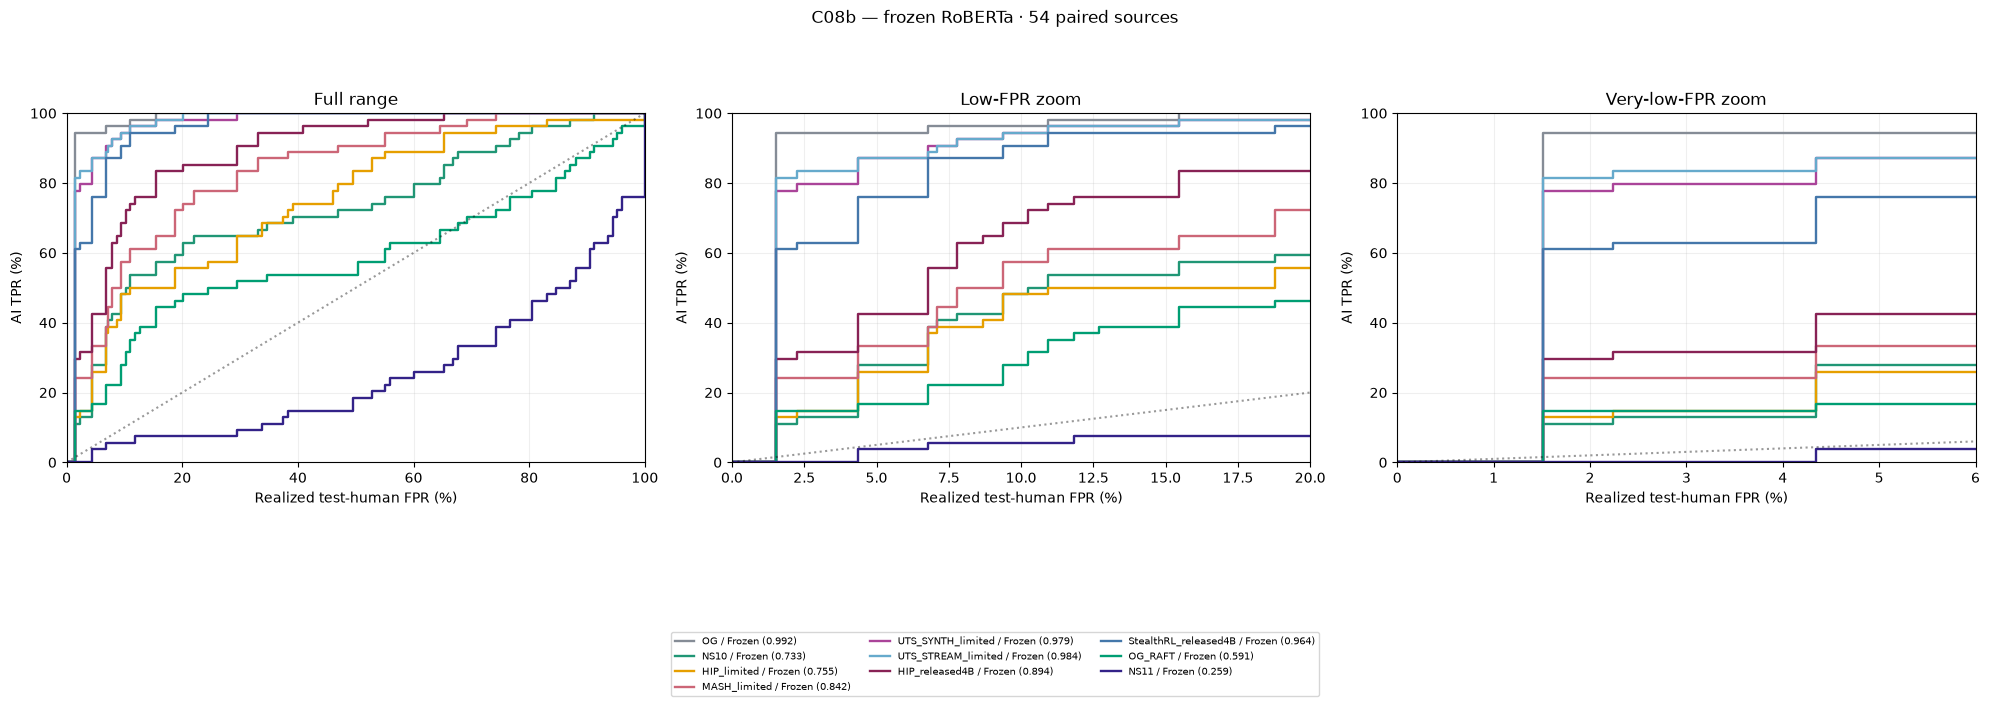

,arm,baseline,delta_AUROC,ci_low,ci_high
0,NS10,OG,-0.258747,-0.334608,-0.186477
1,HIP_limited,OG,-0.236482,-0.305676,-0.176615
2,HIP_limited,NS10,0.022266,-0.076208,0.121831
3,MASH_limited,OG,-0.149904,-0.201861,-0.104875
4,MASH_limited,NS10,0.108843,0.040975,0.178821
5,UTS_SYNTH_limited,OG,-0.012419,-0.027350,-0.000487
6,UTS_SYNTH_limited,NS10,0.246329,0.170614,0.325134
7,UTS_STREAM_limited,OG,-0.007983,-0.020529,0.004104
8,UTS_STREAM_limited,NS10,0.250765,0.177264,0.327701
9,HIP_released4B,OG,-0.097222,-0.133848,-0.064799


Own-arm adaptation: ['NS10', 'HIP_limited', 'OG_RAFT', 'NS11']
Selection uses all 54 outcomes: the subsequent 34-case analysis is exploratory.


In [4]:
COLORS=dict(zip(frames,['#858C96','#209675','#E69F00','#CC6677','#AA4499','#66AACC','#882255','#4477AA','#009E73','#332288']))
def evaluate(scores,ids,detector):
    selected_scores=scores.loc[scores.case_id.isin(ids)]
    mix=ns.set_index('case_id').loc[ids].domain.value_counts(normalize=True)
    refs={}
    for splitname in ['validation','test']:
        f=scores.loc[scores.arm.eq('Human')&scores.split.eq(splitname)&scores.domain.isin(mix.index)].copy()
        counts=f.domain.value_counts();assert set(mix.index)<=set(counts.index)
        f['weight']=[mix[d]/counts[d] for d in f.domain];assert np.isclose(f.weight.sum(),1)
        refs[splitname]=f
    v,h=refs['validation'],refs['test'];vs=v.AI_score.to_numpy();hs=h.AI_score.to_numpy();w=h.weight.to_numpy()
    rows=[];curves=[];parts={};ops=[]
    for arm,f in selected_scores.groupby('arm',sort=False):
        f=f.set_index('case_id').loc[ids];a=f.AI_score.to_numpy()
        c=((a[:,None]>hs)+.5*(a[:,None]==hs))@w;parts[arm]=c
        row=dict(arm=arm,detector=detector,cases=len(ids),AUROC=float(c.mean()),mean_AI_score=float(a.mean()))
        rows.append(row);cuts=np.r_[np.inf,np.unique(vs)[::-1],-np.inf]
        st=pd.DataFrame(dict(arm=arm,detector=detector,threshold=cuts,
            calibration_FPR=[v.weight.to_numpy()[vs>x].sum() for x in cuts],
            test_FPR=[w[hs>x].sum() for x in cuts],TPR=[(a>x).mean() for x in cuts]))
        curves.append((arm,detector,st,row['AUROC']))
        for target in [0,.001,.005,.01,.02,.05,.1,.2,.5,1]:
            r=st.loc[st.calibration_FPR<=target+1e-12].iloc[-1].to_dict();ops.append(dict(target_FPR=target,**r))
    return pd.DataFrame(rows),curves,parts,pd.DataFrame(ops),refs

def plot(curves,title,stem):
    fig,axes=plt.subplots(1,3,figsize=(20,7))
    for ax,(xl,title2) in zip(axes,[((0,100),'Full range'),((0,20),'Low-FPR zoom'),((0,6),'Very-low-FPR zoom')]):
        for arm,det,st,value in curves:
            style={'Frozen':'-','RAID-only continuation':':','Own-arm adapted':'--'}[det]
            ax.step(100*st.test_FPR,100*st.TPR,where='post',color=COLORS[arm],ls=style,lw=1.7,
                label=f'{arm} / {det} ({value:.3f})')
        ax.plot([0,xl[1]],[0,xl[1]],'k:',alpha=.4)
        ax.set(xlim=xl,ylim=(0,100),title=title2,xlabel='Realized test-human FPR (%)',ylabel='AI TPR (%)');ax.grid(alpha=.2)
    handles,labels=axes[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='lower center',fontsize=7,ncol=3)
    fig.suptitle(title);fig.tight_layout(rect=[0,.25,1,.93])
    for folder in [OUT/'figures',ROOT/'figures']:
        folder.mkdir(parents=True,exist_ok=True)
        for ext in ['pdf','png']:fig.savefig(folder/(stem+'.'+ext),dpi=300,bbox_inches='tight')
    plt.show();plt.close(fig)
full,curves,parts,ops,refs=evaluate(frozen_scores,case_ids,'Frozen')
csv(full,OUT/'frozen54_summary.csv');csv(ops,OUT/'frozen54_operating_points.csv')
csv(pd.concat([x[2] for x in curves]),OUT/'frozen54_staircases.csv')
for name,f in refs.items():csv(f,OUT/f'frozen54_{name}_human_scores.csv')
display(full.round(6));plot(curves,'C08b — frozen RoBERTa · 54 paired sources','C08b_RoBERTa_frozen54')
ix=np.random.default_rng(SEED).integers(0,54,size=(5000,54));changes=[]
for arm in frames:
    if arm=='OG':continue
    for baseline in ['OG','NS10']:
        if arm==baseline:continue
        d=parts[arm]-parts[baseline];lo,hi=np.quantile(d[ix].mean(1),[.025,.975])
        changes.append(dict(arm=arm,baseline=baseline,delta_AUROC=d.mean(),ci_low=lo,ci_high=hi))
csv(pd.DataFrame(changes),OUT/'frozen54_paired_changes.csv');display(pd.DataFrame(changes).round(6))
selected=full.loc[full.arm.ne('OG')&full.AUROC.lt(.8),'arm'].tolist()
freeze(OUT/'selected.json',dict(rule='all non-OG arms with frozen full54 AUROC < .8',arms=selected))
print('Own-arm adaptation:',selected)
print('Selection uses all 54 outcomes: the subsequent 34-case analysis is exploratory.')


## Resumable own-arm adaptation and graphs

RAID_only : 1272 training rows; resume: frozen C07b


Step,Training Loss,Validation Loss
25,0.045100,0.147863
50,0.072300,0.179923
75,0.194800,0.172100
100,0.161200,0.501829
125,0.003000,0.201929
150,0.122800,0.301416
175,0.064700,0.193066
200,0.070500,0.157548
225,0.066300,0.292790


RAID-only continuation: 1/409 new scores saved
RAID-only continuation: 25/409 new scores saved
RAID-only continuation: 50/409 new scores saved
RAID-only continuation: 75/409 new scores saved
RAID-only continuation: 100/409 new scores saved
RAID-only continuation: 125/409 new scores saved
RAID-only continuation: 150/409 new scores saved
RAID-only continuation: 175/409 new scores saved
RAID-only continuation: 200/409 new scores saved
RAID-only continuation: 225/409 new scores saved
RAID-only continuation: 250/409 new scores saved
RAID-only continuation: 275/409 new scores saved
RAID-only continuation: 300/409 new scores saved
RAID-only continuation: 325/409 new scores saved
RAID-only continuation: 350/409 new scores saved
RAID-only continuation: 375/409 new scores saved
RAID-only continuation: 400/409 new scores saved
NS10 : 1292 training rows; resume: frozen C07b


Step,Training Loss,Validation Loss
25,0.080900,0.233231
50,0.204600,0.234281
75,0.114200,0.171531
100,0.084300,0.218868
125,0.020600,0.206007
150,0.097900,0.275391
175,0.034900,0.168424
200,0.007900,0.278522
225,0.037700,0.258717


NS10 adapted: 1/307 new scores saved
NS10 adapted: 25/307 new scores saved
NS10 adapted: 50/307 new scores saved
NS10 adapted: 75/307 new scores saved
NS10 adapted: 100/307 new scores saved
NS10 adapted: 125/307 new scores saved
NS10 adapted: 150/307 new scores saved
NS10 adapted: 175/307 new scores saved
NS10 adapted: 200/307 new scores saved
NS10 adapted: 225/307 new scores saved
NS10 adapted: 250/307 new scores saved
NS10 adapted: 275/307 new scores saved
NS10 adapted: 300/307 new scores saved
HIP_limited : 1292 training rows; resume: frozen C07b


...

OG_RAFT adapted: 1/307 new scores saved
OG_RAFT adapted: 25/307 new scores saved
OG_RAFT adapted: 50/307 new scores saved
OG_RAFT adapted: 75/307 new scores saved
OG_RAFT adapted: 100/307 new scores saved
OG_RAFT adapted: 125/307 new scores saved
OG_RAFT adapted: 150/307 new scores saved
OG_RAFT adapted: 175/307 new scores saved
OG_RAFT adapted: 200/307 new scores saved
OG_RAFT adapted: 225/307 new scores saved
OG_RAFT adapted: 250/307 new scores saved
OG_RAFT adapted: 275/307 new scores saved
OG_RAFT adapted: 300/307 new scores saved
NS11 : 1292 training rows; resume: frozen C07b


Step,Training Loss,Validation Loss
25,0.095100,0.200188
50,0.151600,0.220704
75,0.118300,0.127388
100,0.085600,0.157926
125,0.044800,0.165838
150,0.096200,0.199677
175,0.034900,0.158614
200,0.041800,0.177958
225,0.076900,0.174046


NS11 adapted: 1/307 new scores saved
NS11 adapted: 25/307 new scores saved
NS11 adapted: 50/307 new scores saved
NS11 adapted: 75/307 new scores saved
NS11 adapted: 100/307 new scores saved
NS11 adapted: 125/307 new scores saved
NS11 adapted: 150/307 new scores saved
NS11 adapted: 175/307 new scores saved
NS11 adapted: 200/307 new scores saved
NS11 adapted: 225/307 new scores saved
NS11 adapted: 250/307 new scores saved
NS11 adapted: 275/307 new scores saved
NS11 adapted: 300/307 new scores saved


,arm,detector,cases,AUROC,mean_AI_score
0,NS10,Frozen,34,0.729107,0.186319
1,HIP_limited,Frozen,34,0.757849,0.216602
2,OG_RAFT,Frozen,34,0.597682,0.210648
3,NS11,Frozen,34,0.274724,0.017764
4,NS10,RAID-only continuation,34,0.754473,0.357931
5,HIP_limited,RAID-only continuation,34,0.767912,0.270060
6,OG_RAFT,RAID-only continuation,34,0.654472,0.300019
7,NS11,RAID-only continuation,34,0.348399,0.060328
8,NS10,Own-arm adapted,34,0.960164,0.893519
9,HIP_limited,Own-arm adapted,34,0.889135,0.520168


,arm,comparison,delta_AUROC,ci_low,ci_high
0,NS10,Own-arm adapted minus Frozen,0.231057,0.148345,0.322816
1,NS10,Own-arm adapted minus RAID-only continuation,0.205691,0.129887,0.290785
2,HIP_limited,Own-arm adapted minus Frozen,0.131285,0.084134,0.181209
3,HIP_limited,Own-arm adapted minus RAID-only continuation,0.121223,0.079214,0.167135
4,OG_RAFT,Own-arm adapted minus Frozen,0.294509,0.196163,0.401352
5,OG_RAFT,Own-arm adapted minus RAID-only continuation,0.237719,0.156701,0.328184
6,NS11,Own-arm adapted minus Frozen,0.527800,0.440029,0.606860
7,NS11,Own-arm adapted minus RAID-only continuation,0.454125,0.353684,0.546778


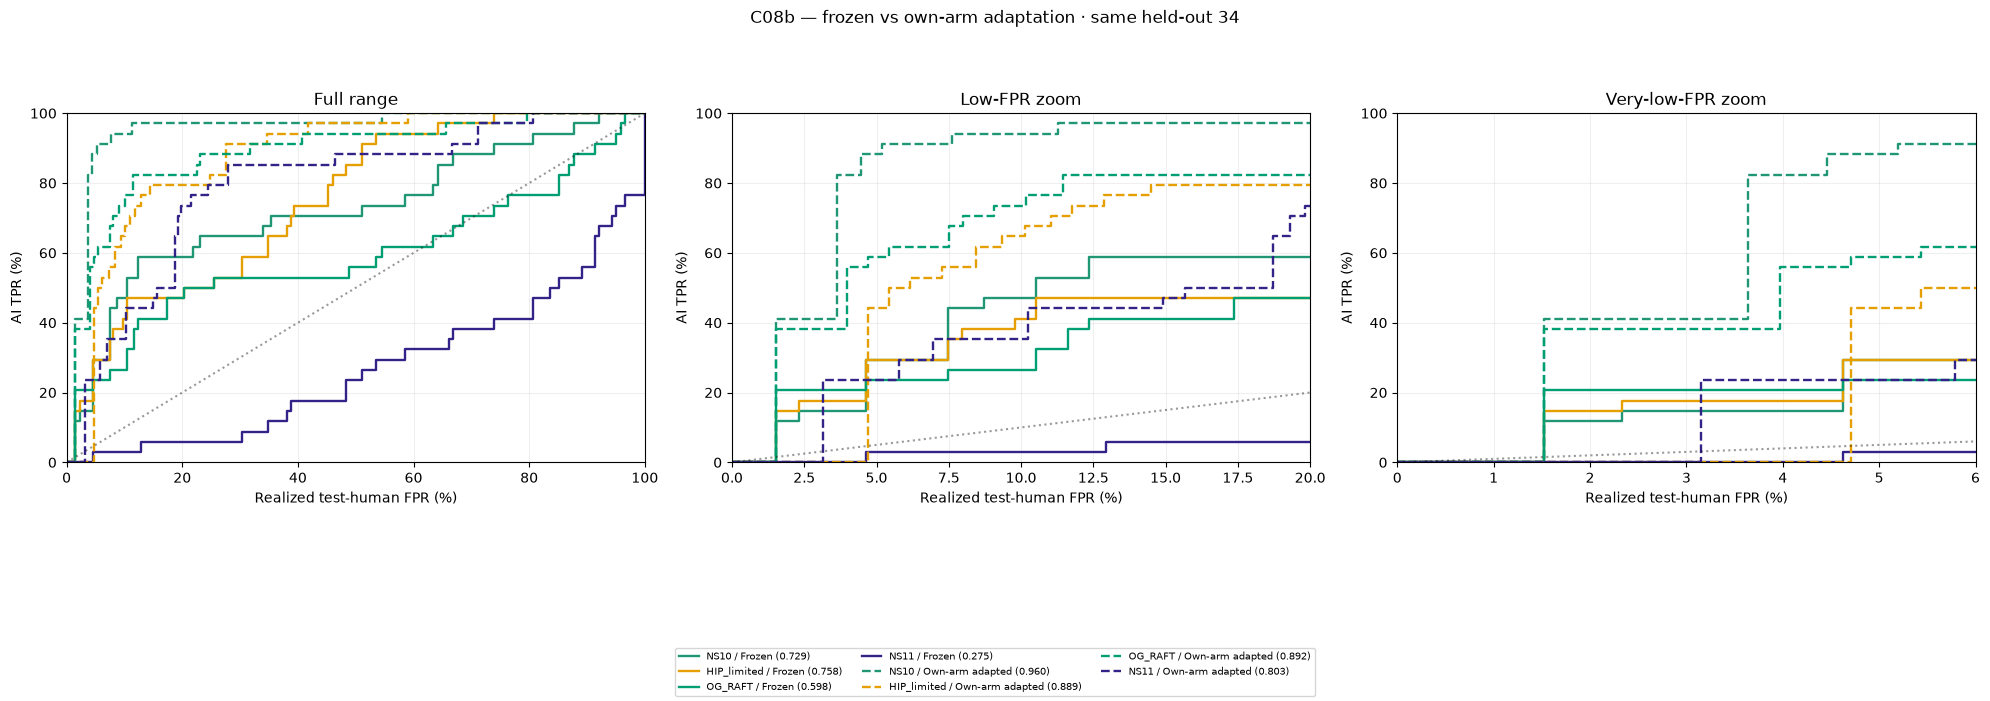

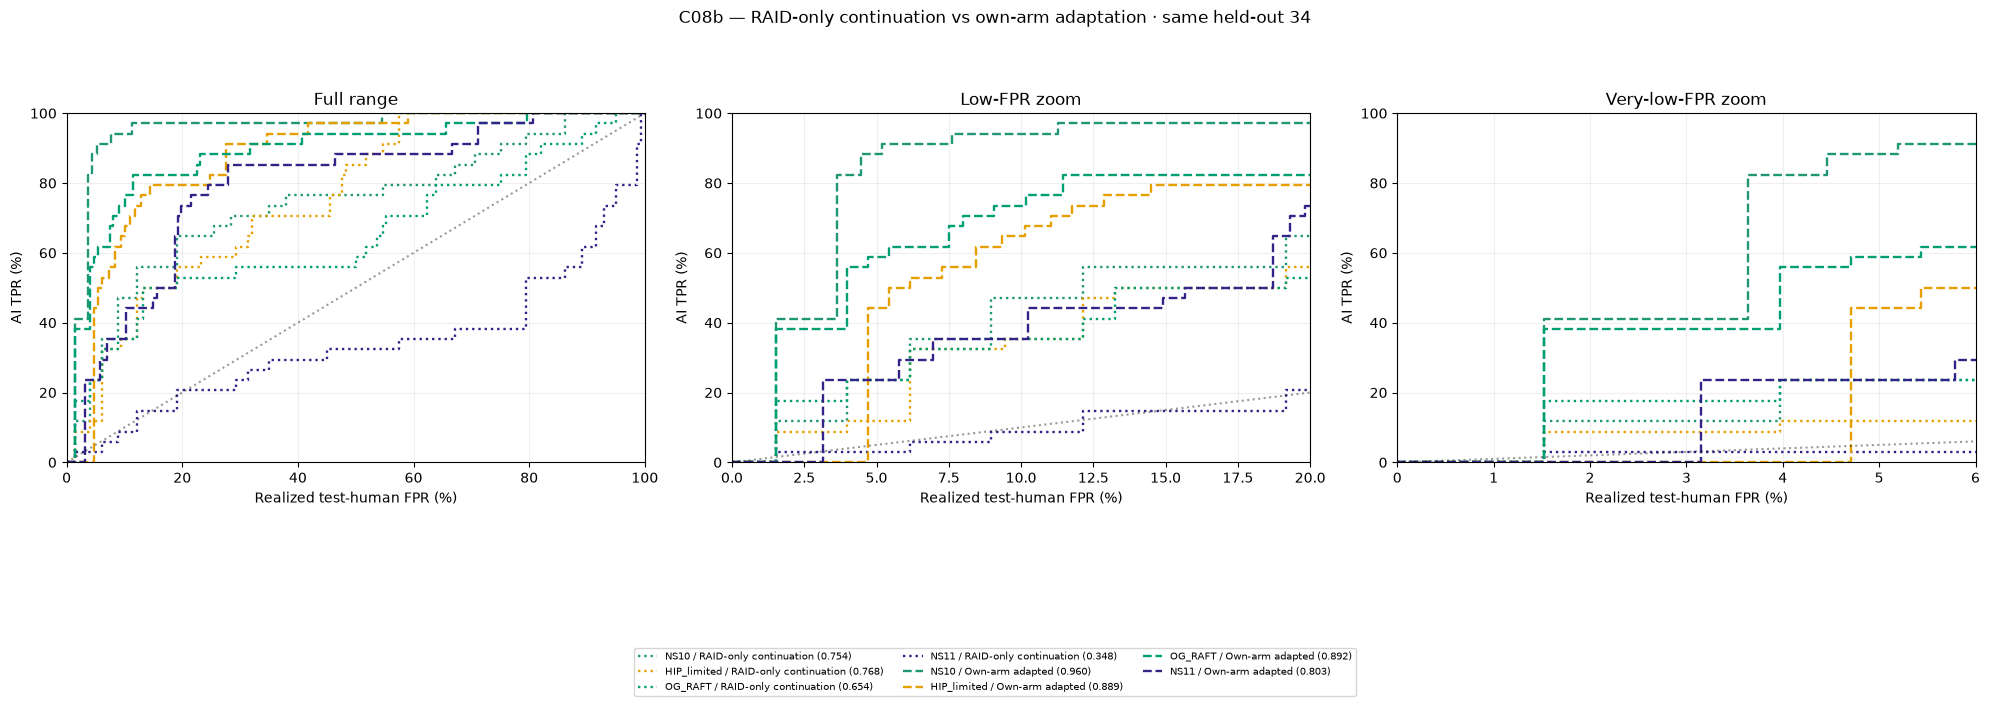

Saved: ../results/causal/C08b_RoBERTa_competitors_RAFT_NS11_v1


In [5]:
class TextDataset(torch.utils.data.Dataset):
    def __init__(self,f):
        self.enc=tok(f.text.tolist(),truncation=True,max_length=512);self.labels=f.label.astype(int).tolist()
    def __len__(self):return len(self.labels)
    def __getitem__(self,i):return {**{k:v[i] for k,v in self.enc.items()},'labels':self.labels[i]}

def train_continuation(name,fit):
    folder=OUT/'adaptation'/name;folder.mkdir(parents=True,exist_ok=True)
    best=folder/'best_model';done=folder/'done.json';train_dir=folder/'training'
    manifest=fit[['source_id','label','text_sha']].to_dict('records')
    freeze(folder/'training_inputs.json',manifest)
    if done.exists():
        assert json.loads(done.read_text())['weights']==fingerprint(best)
        print(name,': saved model reused');return best
    args=copy.deepcopy(reference_args)
    args.output_dir=str(train_dir);args.logging_dir=str(folder/'logs');args.run_name='C08b_'+name
    args.report_to=[];args.push_to_hub=False;args.hub_model_id=None;args.hub_token=None
    args.dataloader_num_workers=0
    train_dir.mkdir(exist_ok=True);set_seed(args.seed);model=trainer=None
    try:
        release();model=AutoModelForSequenceClassification.from_pretrained(FROZEN,
            torch_dtype=torch.float32,attn_implementation='eager',low_cpu_mem_usage=True)
        kwargs=dict(model=model,args=args,train_dataset=TextDataset(fit),eval_dataset=TextDataset(va),
            data_collator=DataCollatorWithPadding(tok,pad_to_multiple_of=8))
        key='processing_class' if 'processing_class' in inspect.signature(Trainer.__init__).parameters else 'tokenizer'
        kwargs[key]=tok;trainer=Trainer(**kwargs)
        last=get_last_checkpoint(str(train_dir))
        print(name,':',len(fit),'training rows; resume:',last or 'frozen C07b',flush=True)
        trainer.train(resume_from_checkpoint=last)
        trainer.save_model(str(best));tok.save_pretrained(best)
        write_json(folder/'training_log.json',trainer.state.log_history)
        write_json(done,dict(weights=fingerprint(best),step=trainer.state.global_step,
            best_validation_loss=float(trainer.state.best_metric)))
    finally:
        del trainer,model;release()
    return best

with lock():
    if selected:
        # Same continuation budget, without attack examples, controls extra training.
        control=train_continuation('RAID_only',tr)
        evaldocs=pd.concat([H.assign(arm='Human',case_id=''),*[frames[a].loc[frames[a].case_id.isin(held)] for a in selected]],ignore_index=True)
        control_scores=score_checkpoint(control,evaldocs,'RAID-only continuation')
        csv(control_scores,OUT/'control34_scores.csv')
        fr=evaluate(frozen_scores.loc[frozen_scores.arm.isin(['Human',*selected])],held,'Frozen')
        co=evaluate(control_scores,held,'RAID-only continuation')
        rows=[fr[0],co[0]];combined=fr[1]+co[1];operating=[fr[3],co[3]];deltas=[]
        for arm in selected:
            extra=frames[arm].loc[frames[arm].case_id.isin(chosen)].sort_values('case_id')
            fit=pd.concat([tr,extra],ignore_index=True)
            assert len(extra)==20
            cp=train_continuation(arm,fit)
            arm_docs=evaldocs.loc[evaldocs.arm.isin(['Human',arm])]
            scored=score_checkpoint(cp,arm_docs,arm+' adapted')
            folder=OUT/'adaptation'/arm;csv(scored,folder/'scores34_and_humans.csv')
            ev=evaluate(scored,held,'Own-arm adapted')
            rows.append(ev[0]);combined+=ev[1];operating.append(ev[3])
            for splitname,f in ev[4].items():csv(f,folder/f'{splitname}_human_scores.csv')
            draws=np.random.default_rng(SEED).integers(0,34,size=(5000,34))
            for baseline,parts0 in [('Frozen',fr[2]),('RAID-only continuation',co[2])]:
                d=ev[2][arm]-parts0[arm];lo,hi=np.quantile(d[draws].mean(1),[.025,.975])
                deltas.append(dict(arm=arm,comparison='Own-arm adapted minus '+baseline,delta_AUROC=d.mean(),ci_low=lo,ci_high=hi))
        summary=pd.concat(rows,ignore_index=True);csv(summary,OUT/'adapted34_summary.csv')
        csv(pd.concat(operating),OUT/'adapted34_operating_points.csv')
        csv(pd.concat([x[2] for x in combined]),OUT/'adapted34_staircases.csv')
        csv(pd.DataFrame(deltas),OUT/'adapted34_paired_changes.csv')
        display(summary.round(6));display(pd.DataFrame(deltas).round(6))
        # Two shared figures keep many selected arms legible without duplicating baselines per arm.
        plot([x for x in combined if x[1]!='RAID-only continuation'],
            'C08b — frozen vs own-arm adaptation · same held-out 34','C08b_RoBERTa_adaptation34')
        plot([x for x in combined if x[1]!='Frozen'],
            'C08b — RAID-only continuation vs own-arm adaptation · same held-out 34','C08b_RoBERTa_control34')
    else:print('No arm qualifies; no adaptation training started.')
print('Saved:',OUT)
